In [8]:
from typing import List , TypedDict
from langgraph.graph import StateGraph

In [9]:
class AgentState(TypedDict):
    name : str 
    skills : List[str]
    age : str
    result : str

In [10]:
def first_node(state : AgentState) -> AgentState :
    """ node for name """
    state['result'] = f"hai {state['name']}."
    return state

def skills_node(state : AgentState) -> AgentState :
    """ node for skills """
    state['result'] = f"{state['result']} , your skills are  {", ".join(state['skills'])}."
    return state

def age_node(state : AgentState) -> AgentState :
    """ node for age """
    state['result'] = f"{state['result']} your age is {state['age']}"
    return state

In [ ]:
graph = StateGraph(AgentState)

graph.add_node('first_node', first_node)
graph.add_node('skills_node', skills_node)
graph.add_node('age_node', age_node)

graph.set_entry_point('first_node')

graph.add_edge('first_node','skills_node')
graph.add_edge('skills_node', 'age_node')

graph.set_finish_point('age_node')

app = graph.compile()

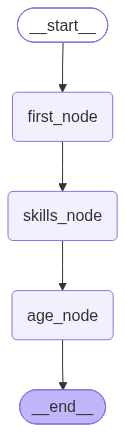

In [12]:
app

In [13]:
res = app.invoke({
    'name': 'dev',
    'skills': ['a', 'b', 'c'],
    'age': 20,

})  # type: ignore

In [14]:
res['result']

'hai dev. , your skills are  a, b, c. your age is 20'